# Moduł przeznaczony do wstępnej analizy danych (rozkłady, wartości, wizualizacja, testy statystyczne)

### import bibliotek

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy.stats import spearmanr, kruskal

## załadowanie zbioru danych - mozemy korzystac tylko ze zbioru połączonych obserwacji

In [4]:
data = pd.read_csv('../data/processed/df_merged.csv', index_col = 0)

## Podstawowe informacje o danych

In [5]:
print(data.head())

   PolicyID  ClaimNb  Exposure Power  CarAge  DriverAge  \
0         1        0      0.09     g       0         46   
1         2        0      0.84     g       0         46   
2         3        0      0.52     f       2         38   
3         4        0      0.45     f       2         38   
4         5        0      0.15     g       0         41   

                                Brand      Gas              Region  Density  \
0  Japanese (except Nissan) or Korean   Diesel           Aquitaine       76   
1  Japanese (except Nissan) or Korean   Diesel           Aquitaine       76   
2  Japanese (except Nissan) or Korean  Regular  Nord-Pas-de-Calais     3003   
3  Japanese (except Nissan) or Korean  Regular  Nord-Pas-de-Calais     3003   
4  Japanese (except Nissan) or Korean   Diesel    Pays-de-la-Loire       60   

   TotalClaimAmount  ClaimCount  
0               0.0         0.0  
1               0.0         0.0  
2               0.0         0.0  
3               0.0         0.0  


In [6]:
print(data.dtypes)

PolicyID              int64
ClaimNb               int64
Exposure            float64
Power                object
CarAge                int64
DriverAge             int64
Brand                object
Gas                  object
Region               object
Density               int64
TotalClaimAmount    float64
ClaimCount          float64
dtype: object


In [7]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
Index: 413169 entries, 0 to 413168
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   PolicyID          413169 non-null  int64  
 1   ClaimNb           413169 non-null  int64  
 2   Exposure          413169 non-null  float64
 3   Power             413169 non-null  object 
 4   CarAge            413169 non-null  int64  
 5   DriverAge         413169 non-null  int64  
 6   Brand             413169 non-null  object 
 7   Gas               413169 non-null  object 
 8   Region            413169 non-null  object 
 9   Density           413169 non-null  int64  
 10  TotalClaimAmount  413169 non-null  float64
 11  ClaimCount        413169 non-null  float64
dtypes: float64(3), int64(5), object(4)
memory usage: 41.0+ MB
None


## Rozkłady zmiennych ClaimNb, Exposure, ClaimAmount

### Zmienna - ClaimNb

wartosci wystepujace w danych

In [8]:
data["ClaimNb"].value_counts().sort_index()

ClaimNb
0    397779
1     14633
2       726
3        28
4         3
Name: count, dtype: int64

udzial wartosci w danych

In [9]:
claim_dist = (
    data["ClaimNb"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

display(claim_dist.rename("percentage").to_frame())

,percentage
ClaimNb,
0,96.275132
1,3.541650
2,0.175715
3,0.006777
4,0.000726


charakterystyka liczbowa wartosci

In [10]:
print(data['ClaimNb'].describe())

count    413169.000000
mean          0.039163
std           0.204053
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           4.000000
Name: ClaimNb, dtype: float64


wykres rozkladu

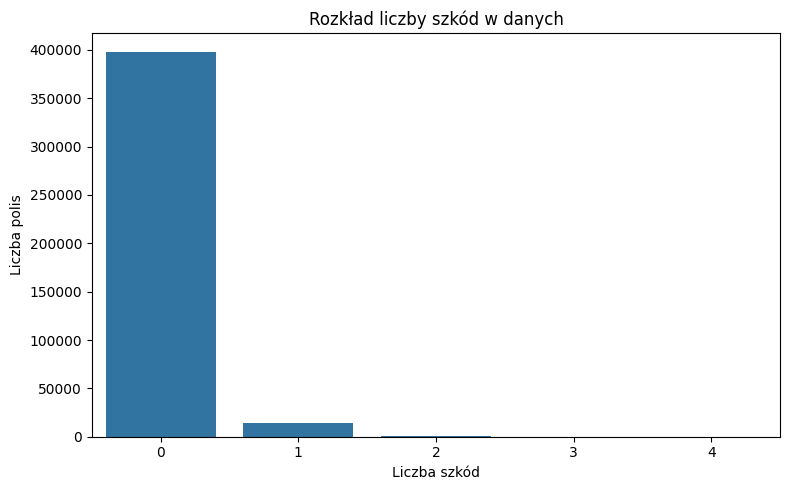

In [11]:

plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="ClaimNb")

plt.title("Rozkład liczby szkód w danych")
plt.xlabel("Liczba szkód")
plt.ylabel("Liczba polis")
plt.tight_layout()
plt.show()

### Zmienna - ekspozycja

In [12]:
data["Exposure"].value_counts().sort_index()

Exposure
0.002732       711
0.002740      1325
0.005464       392
0.005479       811
0.008197       390
             ...  
0.960000      2120
0.970000       971
0.980000      1104
0.990000      1032
1.000000    122038
Name: count, Length: 106, dtype: int64

In [13]:
exposure_dist = (
    data["Exposure"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

display(exposure_dist.rename("percentage").to_frame())

,percentage
Exposure,
0.002732,0.172085
0.002740,0.320692
0.005464,0.094876
0.005479,0.196288
0.008197,0.094392
...,...
0.960000,0.513107
0.970000,0.235013
0.980000,0.267203


In [14]:
print(data['Exposure'].describe())

count    413169.000000
mean          0.560982
std           0.369304
min           0.002732
25%           0.200000
50%           0.540000
75%           1.000000
max           1.000000
Name: Exposure, dtype: float64


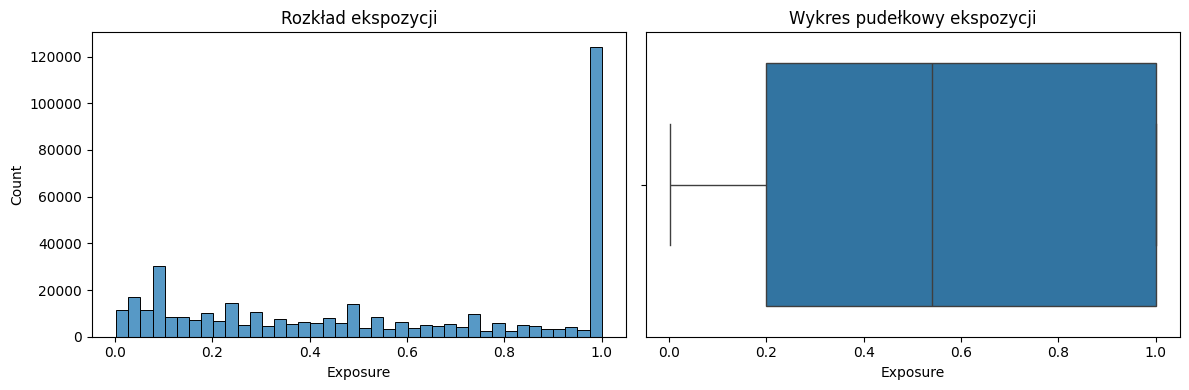

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=data, x="Exposure", bins=40, ax=axes[0])
axes[0].set_title("Rozkład ekspozycji")

sns.boxplot(data=data, x="Exposure", ax=axes[1])
axes[1].set_title("Wykres pudełkowy ekspozycji")

plt.tight_layout()
plt.show()

### Zmienna - TotalClaimsAmount

In [16]:
data["TotalClaimAmount"].value_counts().sort_index()

TotalClaimAmount
0.0          397779
2.0               3
3.0               3
4.0               2
5.0               4
              ...  
281403.0          1
301302.0          1
306559.0          1
1403452.0         1
2036833.0         1
Name: count, Length: 3709, dtype: int64

In [17]:
claim_dist = (
    data[data["TotalClaimAmount"] > 0]['TotalClaimAmount']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

display(claim_dist.rename("percentage").to_frame())

,percentage
TotalClaimAmount,
2.0,0.019493
3.0,0.019493
4.0,0.012995
5.0,0.025991
6.0,0.012995
...,...
281403.0,0.006498
301302.0,0.006498
306559.0,0.006498


In [18]:
print(data['TotalClaimAmount'].describe())

count    4.131690e+05
mean     8.341642e+01
std      4.192526e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.036833e+06
Name: TotalClaimAmount, dtype: float64


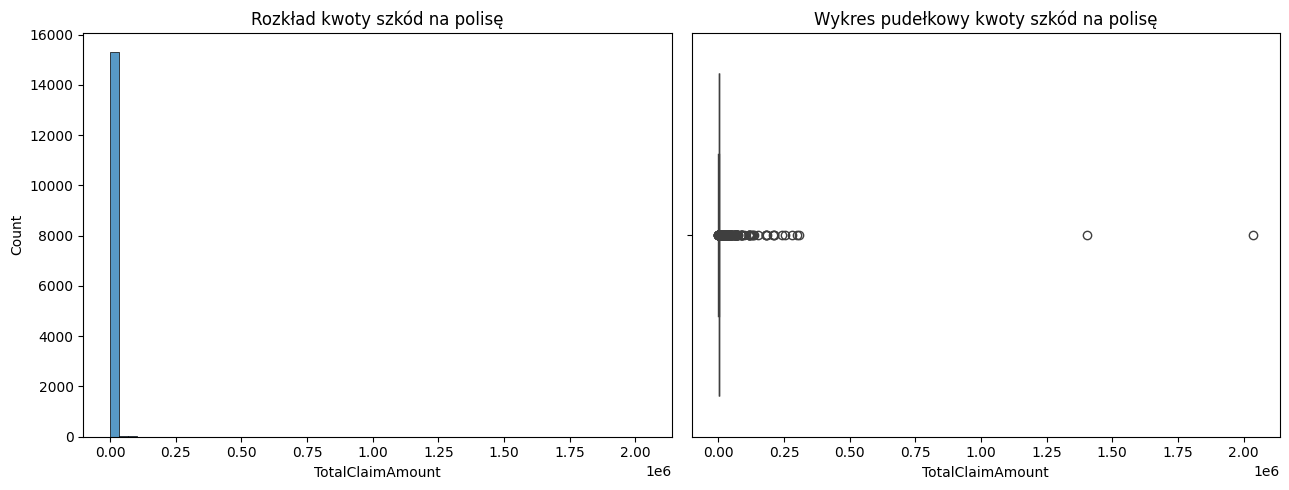

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=data.loc[data['TotalClaimAmount'] > 0, 'TotalClaimAmount'], bins=60, ax=axes[0])
axes[0].set_title("Rozkład kwoty szkód na polisę")

sns.boxplot(data=data.loc[data['TotalClaimAmount'] > 0], x="TotalClaimAmount", ax=axes[1])
axes[1].set_title("Wykres pudełkowy kwoty szkód na polisę")

plt.tight_layout()
plt.show()

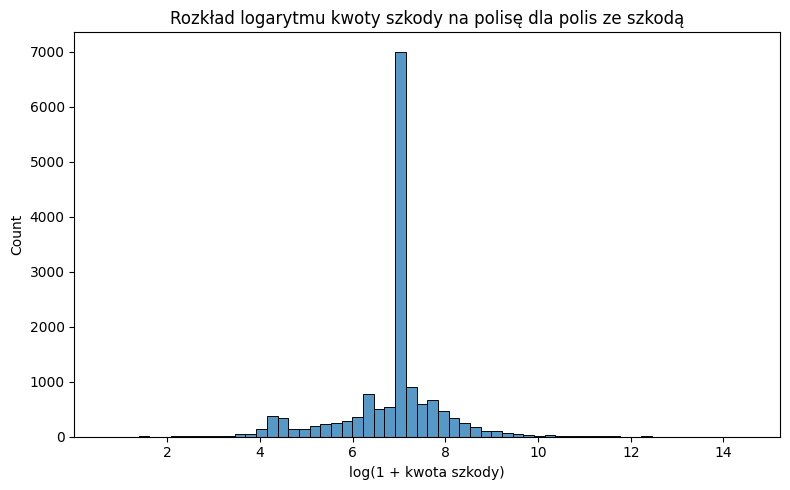

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    np.log(data.loc[data["TotalClaimAmount"] > 0, "TotalClaimAmount"]),
    bins=60
)

plt.title("Rozkład logarytmu kwoty szkody na polisę dla polis ze szkodą")
plt.xlabel("log(1 + kwota szkody)")
plt.tight_layout()
plt.show()

### Analiza danych ze względu na liczbę szkód

In [21]:
claim_summary = (
    data.groupby("ClaimNb", observed=True)
      .agg(
          policies=("ClaimNb", "size"),
          mean_total_claim=("TotalClaimAmount", "mean"),
          median_total_claim=("TotalClaimAmount", "median"),
          total_claims_amount=("TotalClaimAmount", "sum")
      )
)

display(claim_summary)

,policies,mean_total_claim,median_total_claim,total_claims_amount
ClaimNb,,,,
0,397779,0.000000,0.0,0.0
1,14633,2040.914372,1156.0,29864700.0
2,726,6065.068871,2245.0,4403240.0
3,28,6509.285714,3645.5,182260.0
4,3,4959.000000,4811.0,14877.0


### Analiza wartości szkód

In [22]:
claims = data.loc[data["ClaimNb"] > 0].copy()

claims["ClaimSeverity"] = (
    claims["TotalClaimAmount"] / claims["ClaimNb"]
)

display(
    claims["ClaimSeverity"]
    .describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
)

count    1.539000e+04
mean     2.087771e+03
std      1.915374e+04
min      2.000000e+00
50%      1.156000e+03
75%      1.245000e+03
90%      2.583100e+03
95%      4.269100e+03
99%      1.610336e+04
max      2.036833e+06
Name: ClaimSeverity, dtype: float64

## Częstość i wysokość szkody: analiza wartości zmiennych driver_age, veh_age, veh_power, density 

### Zdefiniowanie funkcji, która liczy wielkość i częstotliwość szkód ze względu na zmienną

In [23]:
def variable_analysis(variable, data, columns_dict, categorical, bins = None): 
    
    dataset = data.copy()
    
    if categorical: 
        var_summary = (
            dataset.groupby(variable, observed = True)
            .agg(
                policies = (columns_dict['policy_col'], 'nunique'), 
                claims = (columns_dict['claims_col'], 'sum'), 
                exposure = (columns_dict['exposure_col'], 'sum'), 
                claims_amount = (columns_dict['total_claims_col'], 'sum')
            )
        )
            
        var_summary['Frequency'] = (
                var_summary['claims'] / var_summary['exposure'].replace(0, np.nan)
            )
        
        var_summary['Severity'] = (
            var_summary['claims_amount'] / var_summary['claims'].replace(0, np.nan)
        )
        
    else: 
        dataset[f'{variable}_group'] = pd.cut(
            dataset[variable], 
            bins = bins, 
            right = True
        )
        
        var_summary = (
                    dataset.groupby(f'{variable}_group', observed = True)
                    .agg(
                        policies = (columns_dict['policy_col'], 'nunique'), 
                        claims = (columns_dict['claims_col'], 'sum'), 
                        exposure = (columns_dict['exposure_col'], 'sum'), 
                        claims_amount = (columns_dict['total_claims_col'], 'sum')
                    )
                )
                    
        var_summary['Frequency'] = (
                        var_summary['claims'] / var_summary['exposure'].replace(0, np.nan)
                    )
                
        var_summary['Severity'] = (
                    var_summary['claims_amount'] / var_summary['claims'].replace(0, np.nan)
                )
        
    return var_summary

### Funkcja do wizualizacji podsumowania

In [24]:
def visualize_summary(var_summary, var_name, freq_or_sev): 
    if freq_or_sev not in ['Frequency', 'Severity']: 
        raise(ValueError('Check your data frequency or severity column name. It should be named Frequency or Severity'))
    
    var_summary[freq_or_sev].plot(
        kind = 'bar', 
        figsize = (9, 5)
    )
    
    plt.title(f'{freq_or_sev} by {var_name}')
    plt.xlabel(f'{var_name} group')
    
    if freq_or_sev == 'Frequency': 
        plt.ylabel('Claims per unit of exposure')
    else: 
        plt.ylabel('Severity')
    
    plt.tight_layout()
    plt.show()

### Przygotowanie słownika z kolumnami z naszej ramki danych 

In [25]:
columns_dict = {
    'policy_col': 'PolicyID',
    'claims_col': 'ClaimNb',
    'exposure_col': 'Exposure',
    'total_claims_col': 'TotalClaimAmount'
}

### Zmienna Power

In [26]:
power_summary = variable_analysis('Power', data, columns_dict, 1)
display(power_summary)

,policies,claims,exposure,claims_amount,Frequency,Severity
Power,,,,,,
d,68014,2359,37817.052163,4473851.0,0.062379,1896.503179
e,77022,3201,44628.098402,5583312.0,0.071726,1744.239925
f,95718,3997,55876.264572,9599512.0,0.071533,2401.679259
g,91198,3464,51648.730841,7042145.0,0.067068,2032.951790
h,26698,1000,13915.861796,1733668.0,0.071860,1733.668000
i,17616,722,9409.206840,3270752.0,0.076733,4530.127424
j,18038,710,9276.993851,1374095.0,0.076533,1935.345070
k,9537,380,4697.306749,720268.0,0.080897,1895.442105
l,4681,162,2200.373172,292674.0,0.073624,1806.629630


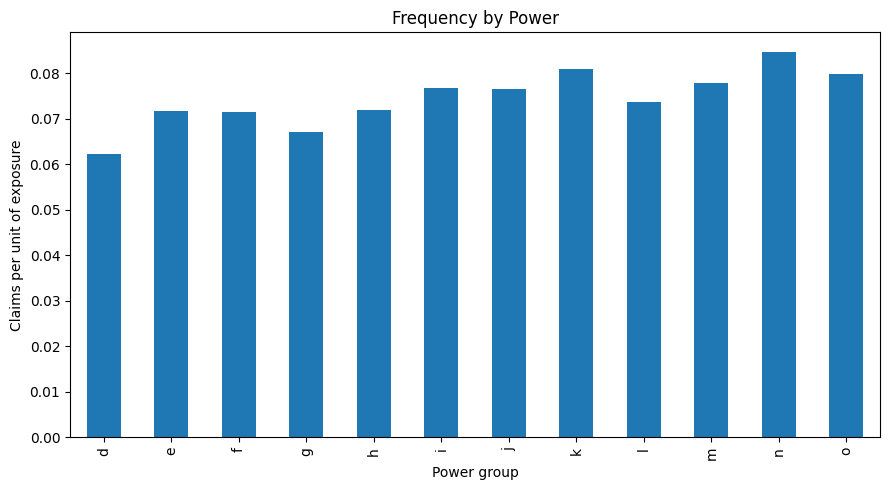

In [27]:
visualize_summary(power_summary, 'Power', 'Frequency')

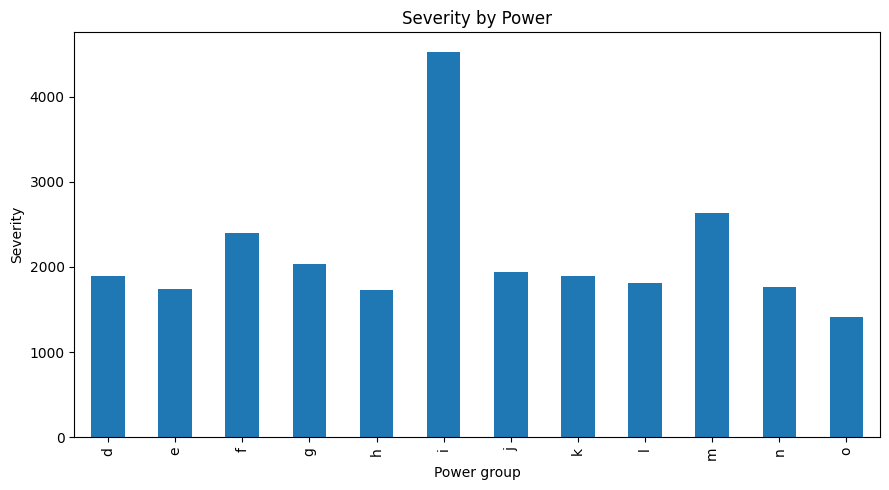

In [28]:
visualize_summary(power_summary, 'Power', 'Severity')

### Zmienna CarAge

bez podzialu na grupy wieku


In [29]:
car_age_summary_const = variable_analysis('CarAge', data, columns_dict, 1)
display(car_age_summary_const)

,policies,claims,exposure,claims_amount,Frequency,Severity
CarAge,,,,,,
0,30049,620,8775.902517,1219098.0,0.070648,1966.287097
1,37772,1314,18160.928724,2955093.0,0.072353,2248.929224
2,32533,1234,17375.018680,2133168.0,0.071022,1728.661264
3,28669,1101,15835.468999,2277330.0,0.069527,2068.419619
4,25776,1086,14981.333589,2196212.0,0.072490,2022.294659
...,...,...,...,...,...,...
83,2,0,0.540000,0.0,0.000000,NaN
84,1,1,1.000000,2882.0,1.000000,2882.000000
85,1,0,0.970000,0.0,0.000000,NaN


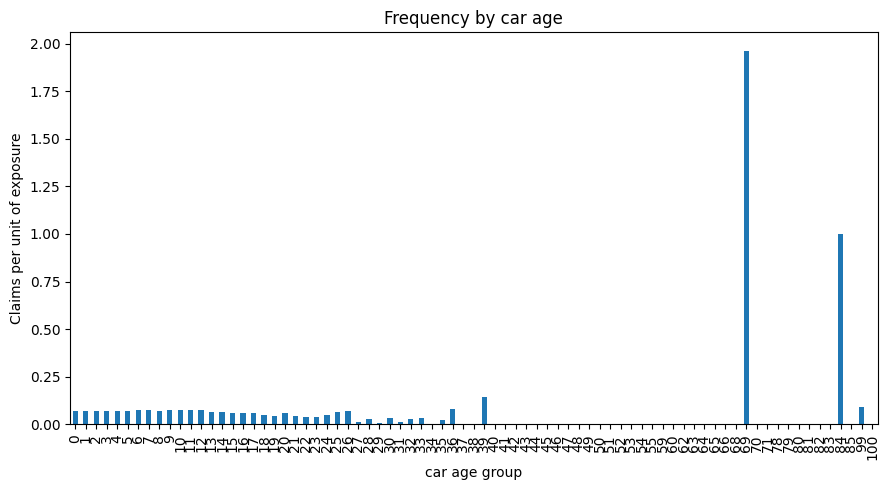

In [32]:
visualize_summary(car_age_summary_const, 'car age', 'Frequency')

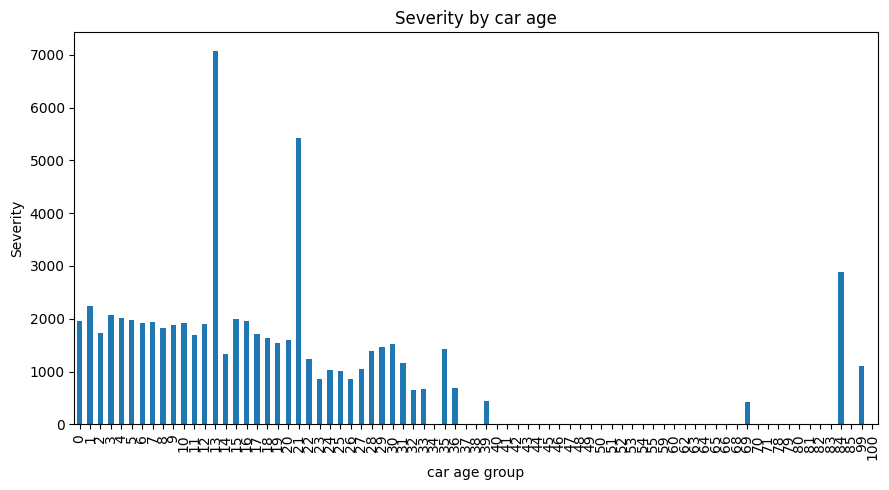

In [33]:
visualize_summary(car_age_summary_const, 'car age', 'Severity')

w podziale na grupy wieku

In [34]:
car_age_bins = [0, 2, 5, 10, 20, 40, 70, 100]
car_age_summary = variable_analysis('CarAge', data, columns_dict, 0, car_age_bins)
display(car_age_summary)

,policies,claims,exposure,claims_amount,Frequency,Severity
CarAge_group,,,,,,
"(0, 2]",70305,2548,35535.947405,5088261.0,0.071702,1996.962716
"(2, 5]",78271,3207,45275.307508,6491985.0,0.070833,2024.317119
"(5, 10]",109435,5025,66338.203391,9540090.0,0.075748,1898.525373
"(10, 20]",119175,4633,72050.658541,11786451.0,0.064302,2544.021368
"(20, 40]",5739,145,3669.200164,334775.0,0.039518,2308.793103
"(40, 70]",142,1,103.062732,425.0,0.009703,425.000000
"(70, 100]",53,2,31.925464,3992.0,0.062646,1996.000000


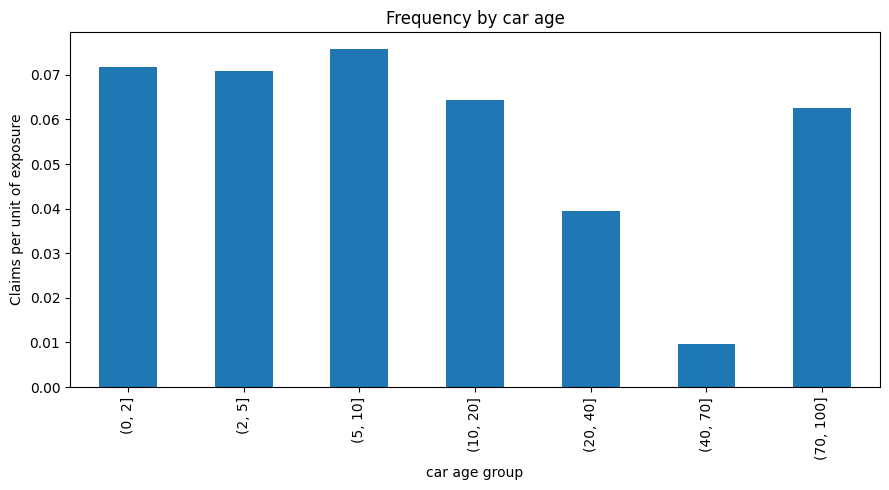

In [29]:
visualize_summary(car_age_summary, 'car age', 'Frequency')

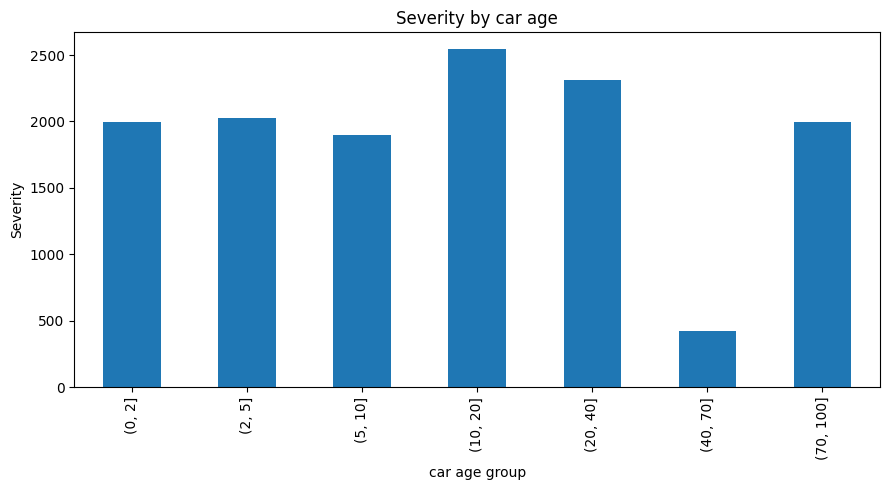

In [30]:
visualize_summary(car_age_summary, 'car age', 'Severity')

### Zmienna DriverAge

bez podzialu na grupy wiekowe

In [36]:
driver_age_summary_const = variable_analysis('DriverAge', data, columns_dict, 1)
display(driver_age_summary_const)

,policies,claims,exposure,claims_amount,Frequency,Severity
DriverAge,,,,,,
18,499,46,149.291995,158154.0,0.308121,3438.130435
19,1614,171,638.459561,2412409.0,0.267832,14107.654971
20,2535,218,1023.504408,1836398.0,0.212994,8423.844037
21,3046,207,1280.958991,918105.0,0.161598,4435.289855
22,3556,241,1567.392729,409704.0,0.153759,1700.016598
...,...,...,...,...,...,...
95,21,2,15.770000,1842.0,0.126823,921.000000
96,12,0,10.990000,0.0,0.000000,NaN
97,9,0,7.600000,0.0,0.000000,NaN


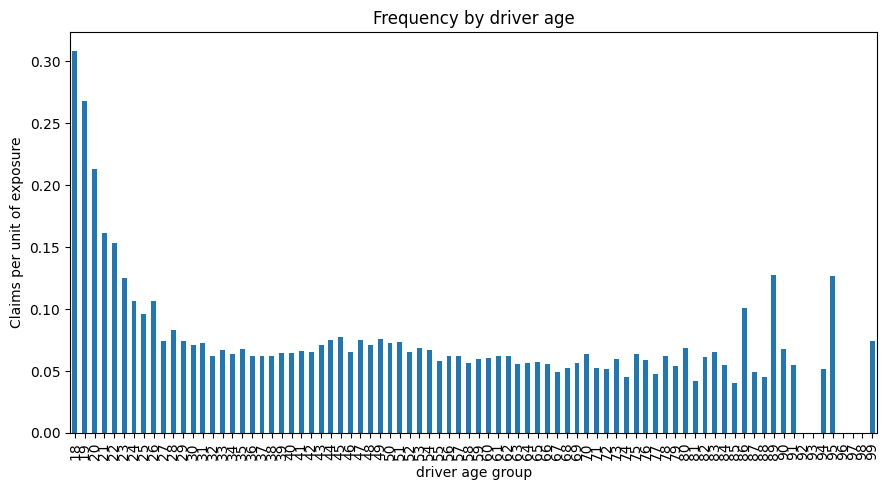

In [37]:
visualize_summary(driver_age_summary_const, 'driver age', 'Frequency')

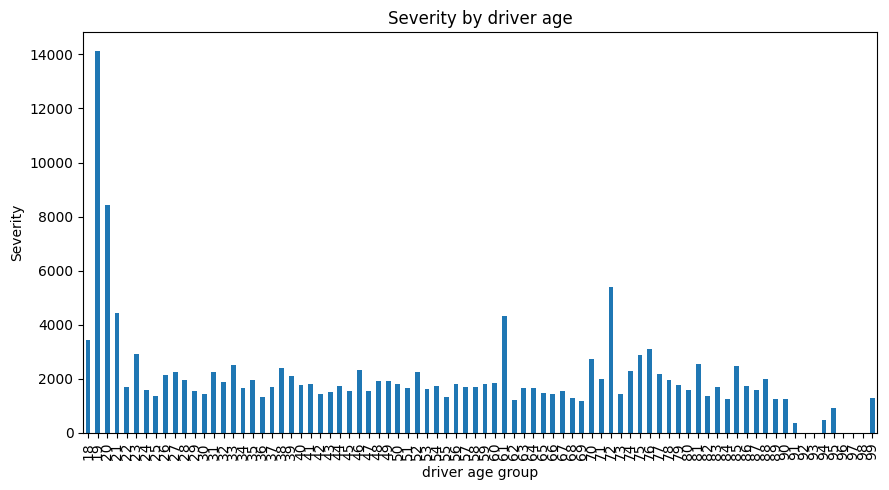

In [38]:
visualize_summary(driver_age_summary_const, 'driver age', 'Severity')

z podzialem

In [31]:
driver_age_bins = [18, 21, 25, 35, 50, 75, 100]
driver_age_summary = variable_analysis('DriverAge', data, columns_dict, 0, driver_age_bins)
display(driver_age_summary)

,policies,claims,exposure,claims_amount,Frequency,Severity
DriverAge_group,,,,,,
"(18, 21]",7195,596,2942.922961,5166912.0,0.202520,8669.315436
"(21, 25]",18169,941,8075.405098,1769318.0,0.116527,1880.252922
"(25, 35]",92314,3253,44989.256321,6387902.0,0.072306,1963.695666
"(35, 50]",152142,5847,85021.091780,10463479.0,0.068771,1789.546605
"(50, 75]",130303,4952,81113.931089,9429955.0,0.061050,1904.272011
"(75, 100]",12547,546,9488.308477,1089357.0,0.057545,1995.159341


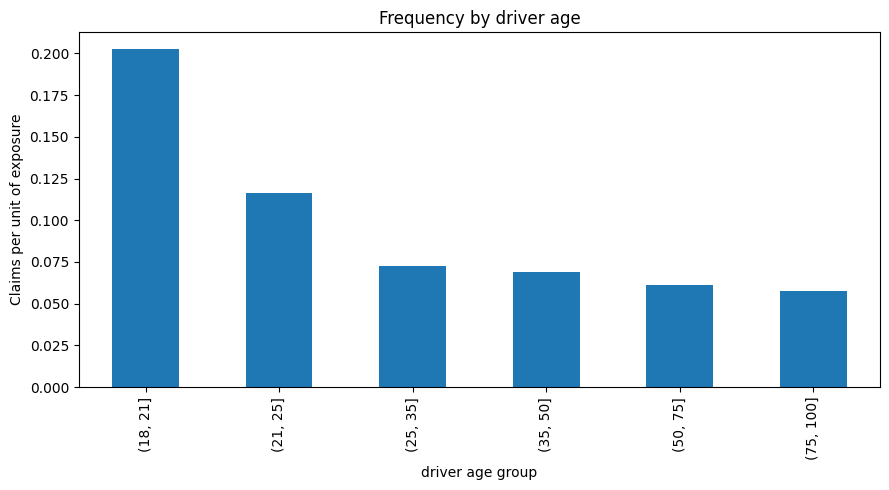

In [32]:
visualize_summary(driver_age_summary, 'driver age', 'Frequency')

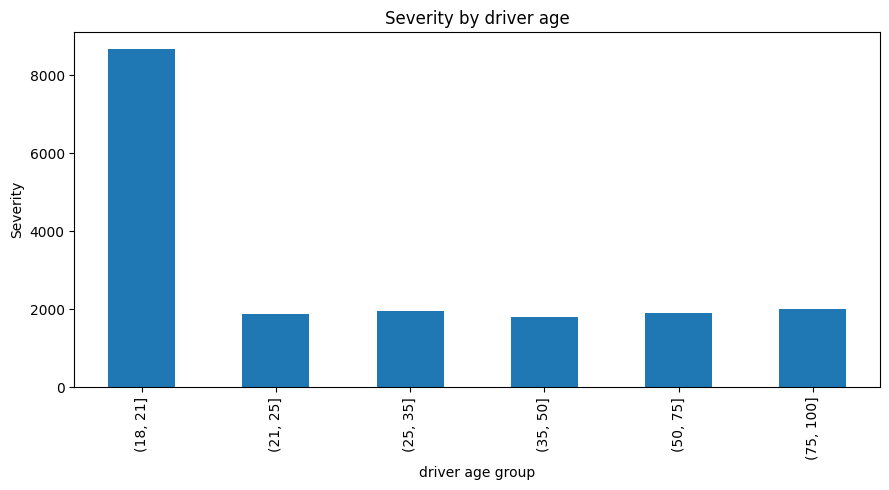

In [33]:
visualize_summary(driver_age_summary, 'driver age', 'Severity')

### Zmienna Brand

In [34]:
brand_summary = variable_analysis('Brand', data, columns_dict, 1)
display(brand_summary)

,policies,claims,exposure,claims_amount,Frequency,Severity
Brand,,,,,,
Fiat,16723,714,9519.620153,1081636.0,0.075003,1514.896359
Japanese (except Nissan) or Korean,79060,2078,31255.696023,4063330.0,0.066484,1955.404235
"Mercedes, Chrysler or BMW",19280,833,10536.934643,1608847.0,0.079055,1931.388956
"Opel, General Motors or Ford",37402,1731,21826.437646,2971817.0,0.079307,1716.820913
"Renault, Nissan or Citroen",218200,8942,134582.209236,20662116.0,0.066443,2310.681727
"Volkswagen, Audi, Skoda or Seat",32638,1470,18295.507372,3208810.0,0.080348,2182.863946
other,9866,413,5763.802649,868521.0,0.071654,2102.956416


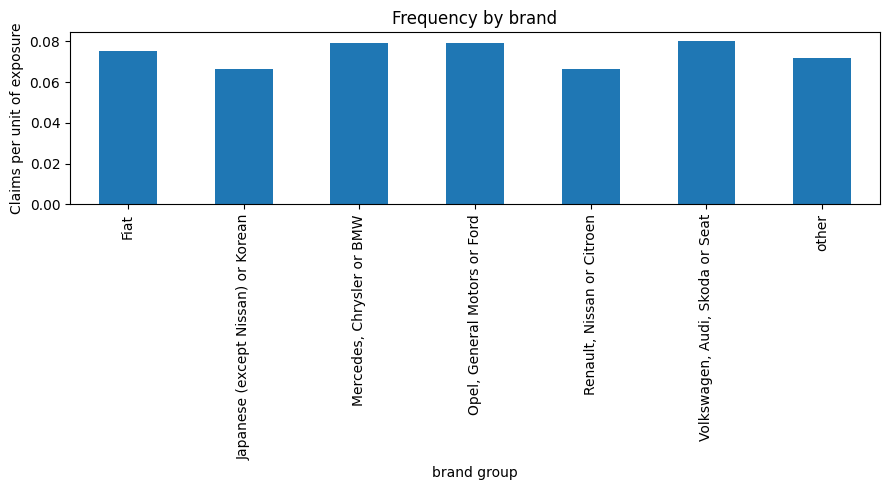

In [35]:
visualize_summary(brand_summary, 'brand', 'Frequency')

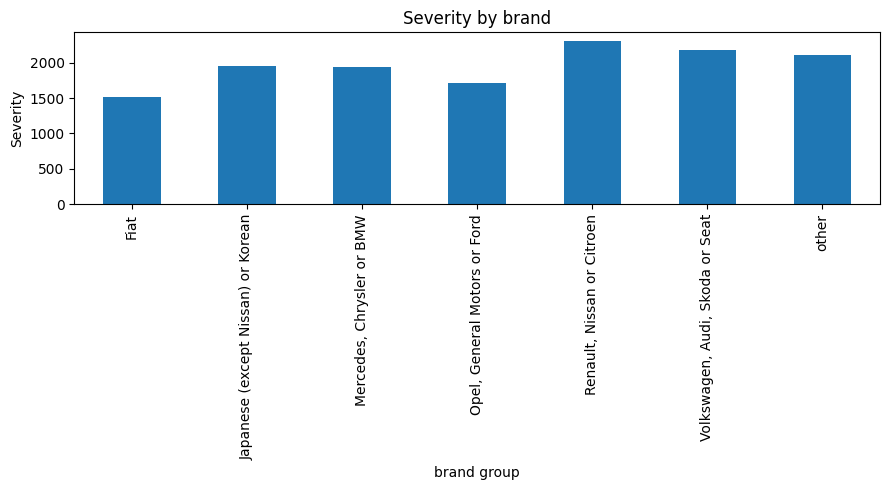

In [36]:
visualize_summary(brand_summary, 'brand', 'Severity')

### Zmienna Gas

In [37]:
gas_summary = variable_analysis('Gas', data, columns_dict, 1)
display(gas_summary)

,policies,claims,exposure,claims_amount,Frequency,Severity
Gas,,,,,,
Diesel,205945,8446,113082.578700,16489534.0,0.074689,1952.348331
Regular,207224,7735,118697.629021,17975543.0,0.065166,2323.922818


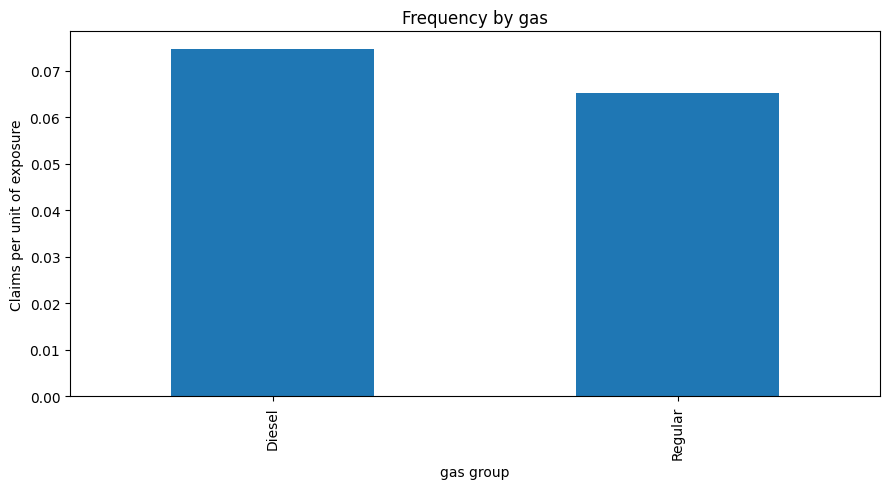

In [38]:
visualize_summary(gas_summary, 'gas', 'Frequency')

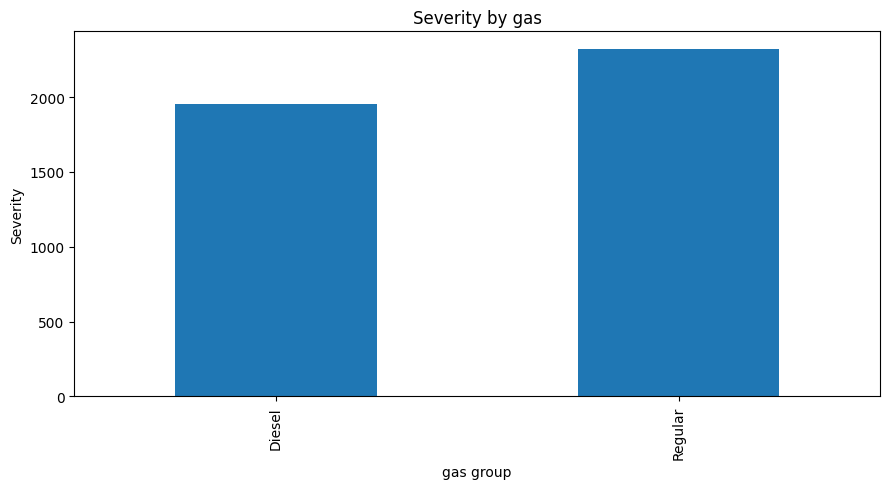

In [39]:
visualize_summary(gas_summary, 'gas', 'Severity')

### Zmienna Region

In [40]:
region_summary = variable_analysis('Region', data, columns_dict, 1)
display(region_summary)

,policies,claims,exposure,claims_amount,Frequency,Severity
Region,,,,,,
Aquitaine,31329,1055,14316.166692,1916319.0,0.073693,1816.416114
Basse-Normandie,10893,452,6652.651142,929312.0,0.067943,2056.000000
Bretagne,42122,1871,27752.793675,3902767.0,0.067417,2085.925708
Centre,160601,6475,102706.443386,17029997.0,0.063044,2630.115367
Haute-Normandie,8784,220,3176.882181,327448.0,0.069250,1488.400000
Ile-de-France,69791,2591,30198.131954,4562281.0,0.085800,1760.818603
Limousin,4567,197,2395.734542,280446.0,0.082229,1423.583756
Nord-Pas-de-Calais,27285,944,11488.074269,1637602.0,0.082172,1734.747881
Pays-de-la-Loire,38751,1576,21930.321165,2572539.0,0.071864,1632.321701


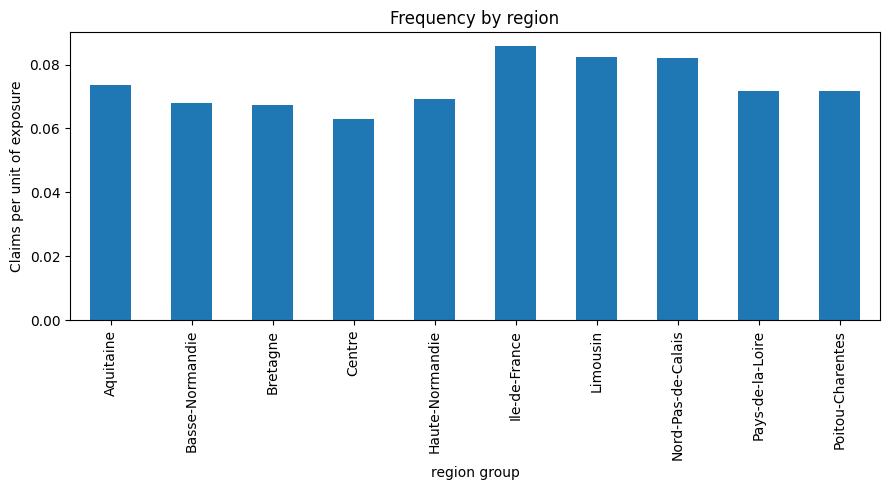

In [41]:
visualize_summary(region_summary, 'region', 'Frequency')

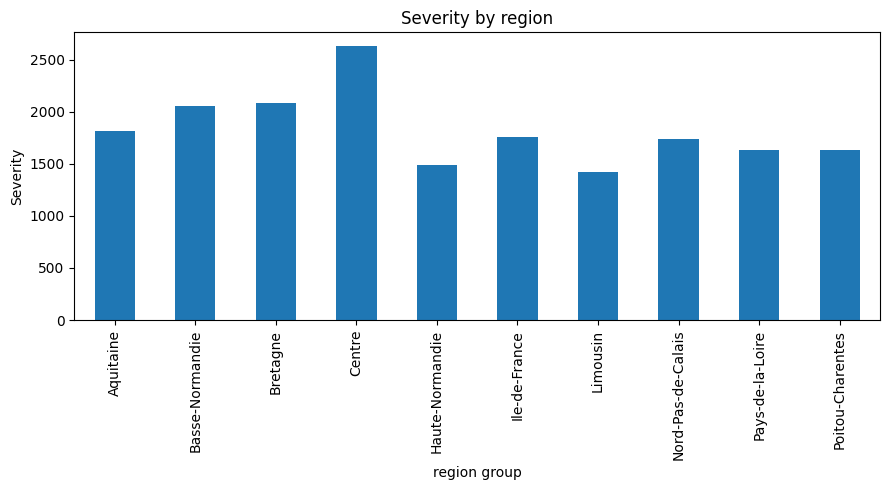

In [42]:
visualize_summary(region_summary, 'region', 'Severity')

### Zmienna Density

bez podzialu na grupy

In [39]:
density_summary_const = variable_analysis('Density', data, columns_dict, 1)
display(density_summary_const)

,policies,claims,exposure,claims_amount,Frequency,Severity
Density,,,,,,
2,18,1,14.070000,428.0,0.071073,428.000000
3,152,4,107.915479,5989.0,0.037066,1497.250000
4,65,1,39.098197,1187.0,0.025577,1187.000000
5,222,12,124.653699,14379.0,0.096267,1198.250000
6,402,11,251.510070,15386.0,0.043736,1398.727273
...,...,...,...,...,...,...
21410,76,8,38.660000,8053.0,0.206932,1006.625000
22669,463,19,202.570959,24106.0,0.093794,1268.736842
22821,182,4,82.282847,4329.0,0.048613,1082.250000


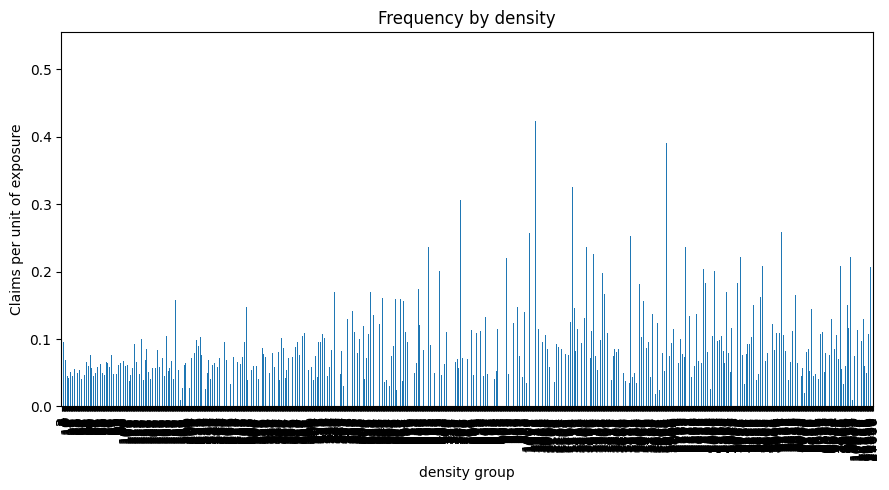

In [40]:
visualize_summary(density_summary_const, 'density', 'Frequency')

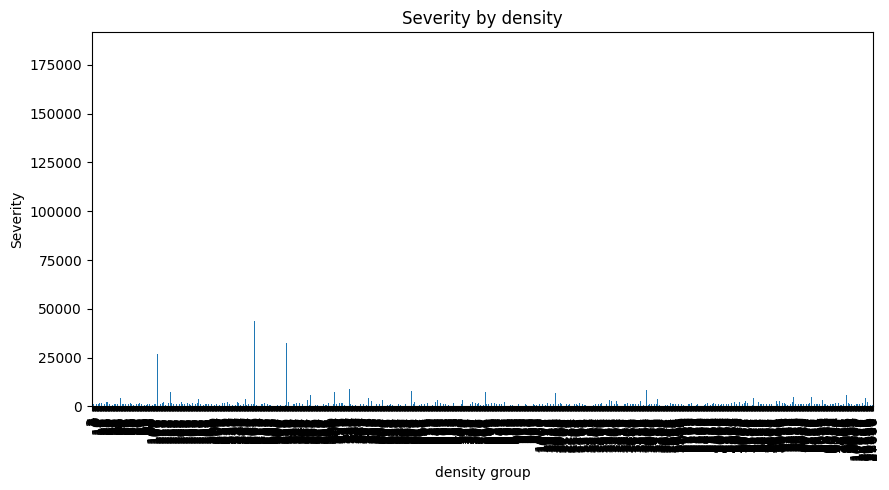

In [41]:
visualize_summary(density_summary_const, 'density', 'Severity')

z podzialem na grupy

In [43]:
density_bins = [0, 10, 50, 150, 400, 800, 1500, 2700]
density_summary = variable_analysis('Density', data, columns_dict, 0, density_bins)
display(density_summary)

,policies,claims,exposure,claims_amount,Frequency,Severity
Density_group,,,,,,
"(0, 10]",5902,196,3882.041018,590796.0,0.050489,3014.265306
"(10, 50]",75371,2569,48071.335055,5836606.0,0.053441,2271.936940
"(50, 150]",80589,3029,48976.329927,7540998.0,0.061846,2489.599868
"(150, 400]",64198,2445,37920.656908,5826325.0,0.064477,2382.955010
"(400, 800]",43161,1818,24696.562036,3403152.0,0.073613,1871.920792
"(800, 1500]",44935,2125,24271.611249,4154044.0,0.087551,1954.844235
"(1500, 2700]",21642,850,9918.434061,1739855.0,0.085699,2046.888235


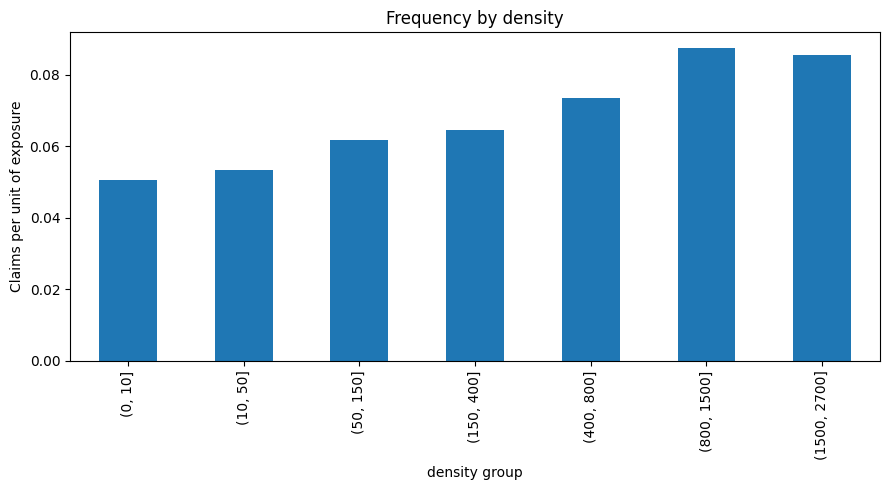

In [44]:
visualize_summary(density_summary, 'density', 'Frequency')

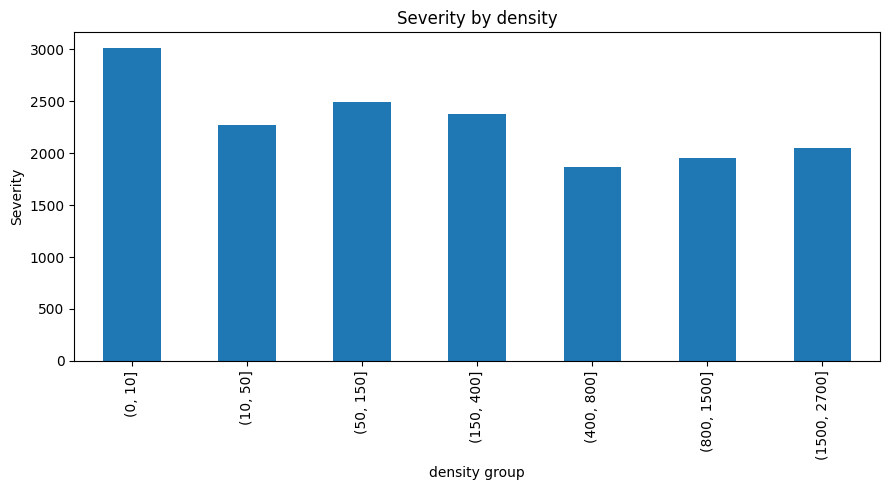

In [45]:
visualize_summary(density_summary, 'density', 'Severity')

## Analiza korelacji dla zmiennych numerycznych i kategorialnych (osobno)

### Stworzenie dodatkowej ramki danych

In [46]:
df_eda = data.copy()

# Frequency na poziomie polisy
df_eda["Frequency"] = (
    df_eda["ClaimNb"] / df_eda["Exposure"].replace(0, np.nan)
)

# Severity na poziomie polisy
df_eda["Severity"] = (
    df_eda["TotalClaimAmount"]
    / df_eda["ClaimNb"].replace(0, np.nan)
)

### Analiza korelacji dla zmiennych numerycznych

In [ ]:
numeric_variables = [
    "DriverAge",
    "CarAge",
    "Power",
    "Density"
]

results = []

for variable in numeric_variables:
    for target in ["Frequency", "Severity"]:
        data_corr = df_eda[[variable, target]].dropna()

        if len(data_corr) < 3 or data_corr[variable].nunique() < 2:
            continue

        corr, p_value = spearmanr(
            data_corr[variable],
            data_corr[target]
        )

        results.append({
            "Variable": variable,
            "Target": target,
            "Spearman_corr": corr,
            "p_value": p_value,
            "n": len(data_corr)
        })

correlation_results = pd.DataFrame(results)
correlation_results

,Variable,Target,Spearman_corr,p_value,n
0,DriverAge,Frequency,-0.006136,8.004475e-05,413169
1,DriverAge,Severity,0.025755,1.396812e-03,15390
2,CarAge,Frequency,0.012080,8.173622e-15,413169
3,CarAge,Severity,-0.029488,2.535228e-04,15390
4,Power,Frequency,0.002755,7.661828e-02,413169
5,Power,Severity,0.016877,3.629358e-02,15390
6,Density,Frequency,0.012251,3.406575e-15,413169
7,Density,Severity,0.022298,5.669269e-03,15390


### Analiza korelacji dla zmiennych kategorialnych

In [ ]:
categorical_variables = [
    "Brand",
    "Gas",
    "Region"
]

results = []

for variable in categorical_variables:
    for target in ["Frequency", "Severity"]:
        data_corr = df_eda[[variable, target]].dropna()

        groups = [
            group[target].to_numpy()
            for _, group in data_corr.groupby(variable, observed=True)
            if len(group) > 0
        ]

        # Test wymaga co najmniej dwóch grup
        # i obserwacji pozwalających na porównanie.
        if len(groups) < 2:
            continue

        statistic, p_value = kruskal(*groups)

        results.append({
            "Variable": variable,
            "Target": target,
            "Kruskal_statistic": statistic,
            "p_value": p_value,
            "n": len(data_corr),
            "n_categories": len(groups)
        })

categorical_results = pd.DataFrame(results)
categorical_results

,Variable,Target,Kruskal_statistic,p_value,n,n_categories
0,Brand,Frequency,483.205114,3.484262e-101,413169,7
1,Brand,Severity,93.856891,4.781683e-18,15390,7
2,Gas,Frequency,36.599283,1.450851e-09,413169,2
3,Gas,Severity,3.247626,7.152699e-02,15390,2
4,Region,Frequency,158.545600,1.489032e-29,413169,10
5,Region,Severity,43.904986,1.469484e-06,15390,10


## Analiza kombinacji kilku zmiennych - jako odpowiedz na niskie korelacje zmiennych ze zmiennymi objaśnianymi

### DriverAge x Power

In [ ]:

df_interaction = data.copy()

age_bins = [17, 24, 34, 44, 54, 64, 74, 100]
age_labels = [
    "18–24", "25–34", "35–44",
    "45–54", "55–64", "65–74", "75–100"
]

df_interaction["DriverAgeGroup"] = pd.cut(
    df_interaction["DriverAge"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

summary = (
    df_interaction
    .groupby(
        ["DriverAgeGroup", "Power"],
        observed=True
    )
    .agg(
        policies=("PolicyID", "nunique"),
        claims=("ClaimNb", "sum"),
        exposure=("Exposure", "sum"),
        claim_amount=("TotalClaimAmount", "sum")
    )
)

summary["Frequency"] = (
    summary["claims"]
    / summary["exposure"].replace(0, np.nan)
)

summary["Severity"] = (
    summary["claim_amount"]
    / summary["claims"].replace(0, np.nan)
)

summary.head()

policies  claims     exposure  claim_amount  Frequency  \
DriverAgeGroup Power                                                           
18–24          d          4754     253  2071.384577      756028.0   0.122141   
               e          4596     316  2113.210308      544842.0   0.149536   
               f          4836     335  2056.567083     2174301.0   0.162893   
               g          3707     253  1537.240213      921046.0   0.164581   
               h           810      62   302.166700      138929.0   0.205185   
...                        ...     ...          ...           ...        ...   
75–100         k           200      15   132.783669       20768.0   0.112966   
               l            58       1    38.448197        1142.0   0.026009   
               m            52       3    40.800000       11383.0   0.073529   
               n            41       0    29.690000           0.0   0.000000   
               o            37       4    15.620000        6251.0   0.256082   

                         Severity  
DriverAgeGroup Power               
18–24          d      2988.252964  
               e      1724.183544  
               f      6490.450746  
               g      3640.498024  
               h      2240.790323  
...                           ...  
75–100         k      1384.533333  
               l      1142.000000  
               m      3794.333333  
               n              NaN  
               o      1562.750000  

[84 rows x 6 columns]

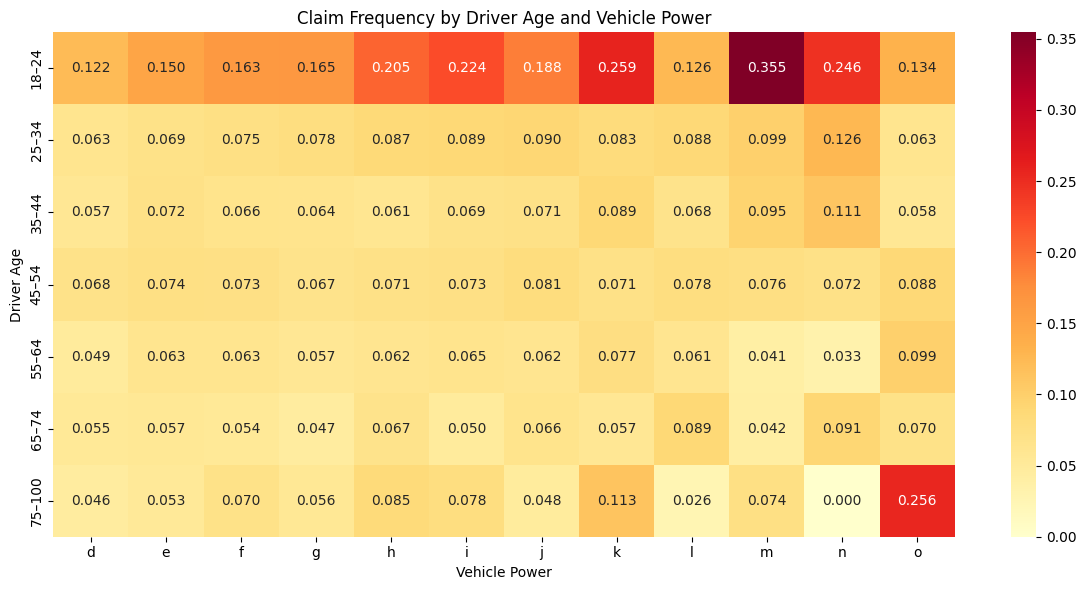

In [55]:
frequency_matrix = (
    summary["Frequency"]
    .unstack("Power")
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    frequency_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd"
)

plt.title("Claim Frequency by Driver Age and Vehicle Power")
plt.xlabel("Vehicle Power")
plt.ylabel("Driver Age")
plt.tight_layout()
plt.show()

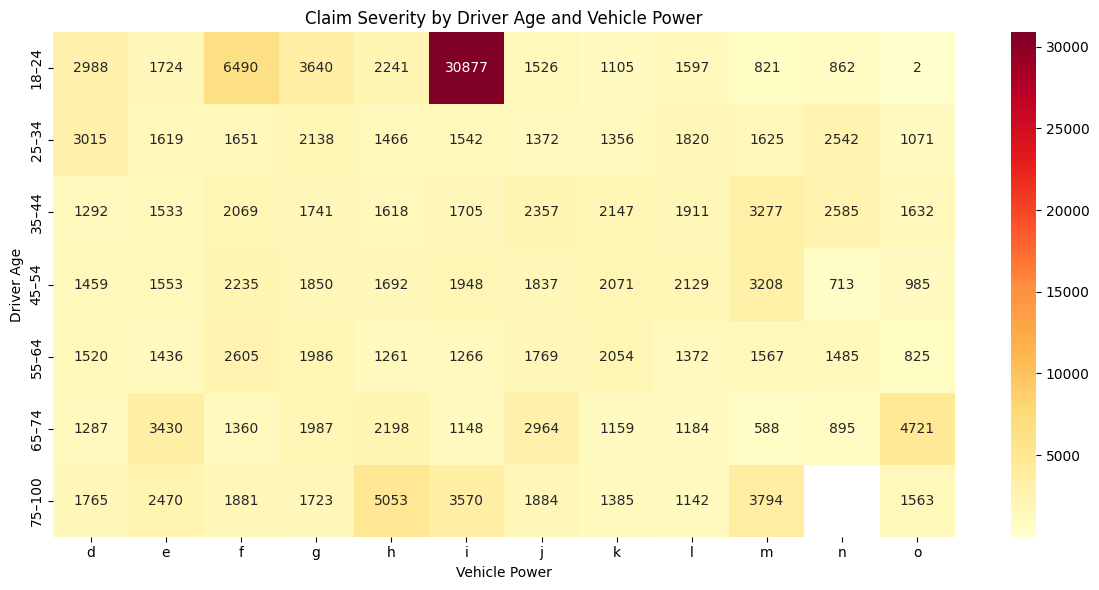

In [56]:
severity_matrix = (
    summary["Severity"]
    .unstack("Power")
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    severity_matrix,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Claim Severity by Driver Age and Vehicle Power")
plt.xlabel("Vehicle Power")
plt.ylabel("Driver Age")
plt.tight_layout()
plt.show()

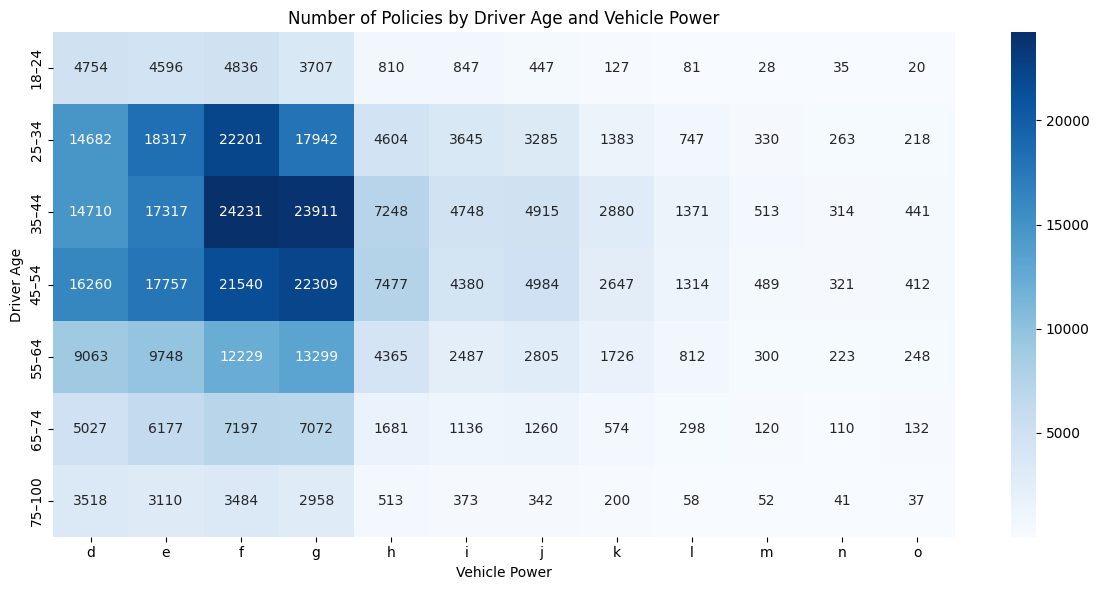

In [57]:
policy_matrix = summary["policies"].unstack("Power")

plt.figure(figsize=(12, 6))

sns.heatmap(
    policy_matrix,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Number of Policies by Driver Age and Vehicle Power")
plt.xlabel("Vehicle Power")
plt.ylabel("Driver Age")
plt.tight_layout()
plt.show()

In [58]:
diagnostics = (
    summary
    .reset_index()
    .sort_values("Frequency", ascending=False)
)

diagnostics[
    [
        "DriverAgeGroup",
        "Power",
        "policies",
        "claims",
        "exposure",
        "claim_amount",
        "Frequency",
        "Severity",
    ]
].head(20)

,DriverAgeGroup,Power,policies,claims,exposure,claim_amount,Frequency,Severity
9,18–24,m,28,3,8.460936,2462.0,0.354571,820.666667
7,18–24,k,127,11,42.550959,12151.0,0.258514,1104.636364
83,75–100,o,37,4,15.620000,6251.0,0.256082,1562.750000
10,18–24,n,35,4,16.252732,3446.0,0.246112,861.500000
5,18–24,i,847,70,312.682984,2161370.0,0.223869,30876.714286
4,18–24,h,810,62,302.166700,138929.0,0.205185,2240.790323
6,18–24,j,447,32,169.935601,48825.0,0.188307,1525.781250
3,18–24,g,3707,253,1537.240213,921046.0,0.164581,3640.498024
2,18–24,f,4836,335,2056.567083,2174301.0,0.162893,6490.450746
1,18–24,e,4596,316,2113.210308,544842.0,0.149536,1724.183544
